### Histogram Equalization in Latent Space

In [1]:
from pathlib import Path
import sys

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
# Import necessary libraries
import os
import sys
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names

# Set the plotting style for better-looking visualizations
plt.style.use('seaborn-v0_8')

In [3]:
# Set a seed for reproducibility
seed_everything(42)

In [4]:
print("Loading train data...")
train_dataloader, val_dataloader, pipeline = load_data(
    train_path = "../../datasets_challenge/train",
    train_ratio = 0.98,  # 🔥 FIX: Was None! Must be 0.98 for 98/2 split
    batchsize = 64,
    columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],
    sequence_length = 20,
    threshold = True,
    threshold_value = 3.0,
    threshold_column = "vxCG",
    target = "sideSlip",
    scaling = True,
    seed = 42,
)

print(f"✅ Data loaded")
print(f"   Train batches: {len(train_dataloader)}")
print(f"   Val batches: {len(val_dataloader) if val_dataloader else 0}")

Loading train data...
../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/tra

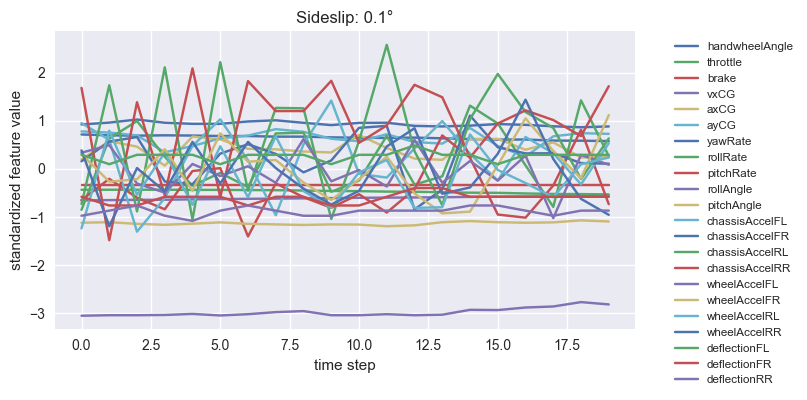

In [5]:
# Get one batch to check dimensions
X, y = next(iter(train_dataloader))

plt.figure(figsize=(8,4))
plt.plot(X[0,:,:], label=feature_names)
plt.title("Sideslip: "+str(round(y[0].item(),2))+"°")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.tight_layout()
plt.xlabel("time step")
plt.ylabel("standardized feature value")
plt.show()

### Modify your RNN to expose latent features

In [6]:
class RNNWithLatent(nn.Module):
    def __init__(self, input_size, rnn_units=64, fc_units=64):
        super().__init__()

        self.rnn = nn.RNN(input_size, rnn_units, batch_first=True)
        self.fc = nn.Linear(rnn_units, fc_units)
        self.out = nn.Linear(fc_units, 1)
        self.act = nn.ReLU()

    def forward(self, x):
        h_seq, _ = self.rnn(x)
        h_last = h_seq[:, -1, :]                  # (batch, rnn_units)
        h_latent = self.act(self.fc(h_last))     # <-- latent vector
        pred = self.out(h_latent)
        return pred, h_latent

### Kernel Density Matching Loss

In [13]:
def kde_loss(latent_few, latent_many, sigma=0.1):
    """
    Differentiable approximation of histogram matching using Gaussian kernels.
    """

    # pairwise distance matrix    shape: (N_few, N_many)
    dist = (latent_few.unsqueeze(1) - latent_many.unsqueeze(0)) ** 2

    # Gaussian kernel — fully differentiable  
    K = torch.exp(-dist / (2 * sigma**2))

    # KDE estimates
    few_density  = K.mean(dim=1)
    many_density = K.mean(dim=0)

    # Compare distributions using MSE
    loss = torch.mean((few_density.mean() - many_density.mean()) ** 2)

    return loss


In [14]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

input_size = X.shape[2]
rnn_units = 64
fc_units = 64
output_size = 1
lr = 0.0003

model = RNNWithLatent(
    input_size=input_size,
    rnn_units=rnn_units,
    fc_units=fc_units,
).to(device)

criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

Using device: cpu
Model parameters: 9,857


In [15]:
num_epochs = 50
early_stop_thresh = 10
best_loss = np.inf
best_epoch = -1
λ_hist = 0.1  

print("\n" + "="*80)
print("🚀 STARTING TRAINING (WITH LATENT HISTOGRAM MATCHING)")
print("="*80)

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for X, y in train_dataloader:

        optimizer.zero_grad()

        # Forward pass
        pred, latent = model(X.to(device))
        y = y.to(device).reshape(-1,1)

        # -----------------------------
        # FEW-SHOT & MANY-SHOT SPLIT
        # -----------------------------
        mask_few  = (y.abs() < 0.015).squeeze()
        mask_many = (y.abs() > 0.05).squeeze()

        if mask_few.sum() > 5 and mask_many.sum() > 5:
            latent_few  = latent[mask_few]
            latent_many = latent[mask_many]
            L_hist = kde_loss(latent_few, latent_many)

        else:
            L_hist = torch.tensor(0.0, device=device)

        # Total loss
        mae_loss = criterion(pred, y)
        total_loss = mae_loss + λ_hist * L_hist

        total_loss.backward()
        optimizer.step()

        running_loss += total_loss.item()

    avg_train_loss = running_loss / len(train_dataloader)
    print(f"Epoch {epoch+1}/{num_epochs} | Train: {avg_train_loss:.5f}")

    # -----------------------------
    # VALIDATION
    # -----------------------------
    if val_dataloader is not None:
        model.eval()
        val_loss_sum = 0.0

        with torch.no_grad():
            for Xv, yv in val_dataloader:
                yv = yv.to(device).reshape(-1,1)
                pred_val, _ = model(Xv.to(device))
                val_loss_sum += criterion(pred_val, yv).item()

        avg_val_loss = val_loss_sum / len(val_dataloader)

        print(f"                  | Val:   {avg_val_loss:.5f}")

        # EARLY STOPPING
        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            best_epoch = epoch

            torch.save({
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': best_loss
            }, "best_model.pth")

            print("                  → 💾 NEW BEST SAVED!")

        elif epoch - best_epoch > early_stop_thresh:
            print(f"\n⏹️ Early stopping at epoch {epoch+1}")
            break


# -----------------------------
# LOAD BEST MODEL
# -----------------------------
checkpoint = torch.load("best_model.pth", map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])

print("\n" + "="*80)
print(f"✅ Best model loaded (epoch {best_epoch+1}) | Val Loss = {best_loss:.5f}")
print("="*80)



🚀 STARTING TRAINING (WITH LATENT HISTOGRAM MATCHING)
Epoch 1/50 | Train: 0.28461
                  | Val:   0.19806
                  → 💾 NEW BEST SAVED!
Epoch 2/50 | Train: 0.19492
                  | Val:   0.18571
                  → 💾 NEW BEST SAVED!
Epoch 3/50 | Train: 0.18135
                  | Val:   0.16494
                  → 💾 NEW BEST SAVED!
Epoch 4/50 | Train: 0.17417
                  | Val:   0.16227
                  → 💾 NEW BEST SAVED!
Epoch 5/50 | Train: 0.16892
                  | Val:   0.18644
Epoch 6/50 | Train: 0.16468
                  | Val:   0.16554
Epoch 7/50 | Train: 0.16118
                  | Val:   0.15326
                  → 💾 NEW BEST SAVED!
Epoch 8/50 | Train: 0.15766
                  | Val:   0.15367
Epoch 9/50 | Train: 0.15564
                  | Val:   0.15635
Epoch 10/50 | Train: 0.15280
                  | Val:   0.14924
                  → 💾 NEW BEST SAVED!
Epoch 11/50 | Train: 0.15075
                  | Val:   0.14655
                  → 💾 N

In [19]:
# Load full training set (NOT shuffled)
train_full = load_test_data(
    test_path="../../datasets_challenge/train",
    batchsize=512,
    pipeline=pipeline,
    load_anonymized_data=False
)

model.eval()
train_preds = []
train_truth = []

with torch.no_grad():
    for Xb, yb in train_full:
        Xb = Xb.to(device)
        yb = yb.to(device).reshape(-1,1)

        pred_b, _ = model(Xb)
        train_preds.append(pred_b.cpu().numpy())
        train_truth.append(yb.cpu().numpy())

train_preds  = np.concatenate(train_preds)
train_truth  = np.concatenate(train_truth)


../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/train\train_part_020.csv


In [25]:
test_dataloader = load_test_data(
    test_path="../../datasets_challenge/test",
    batchsize=64,
    pipeline=pipeline,
    load_anonymized_data=True
)


../../datasets_challenge/test\test_part_001.csv
../../datasets_challenge/test\test_part_002.csv
../../datasets_challenge/test\test_part_003.csv
../../datasets_challenge/test\test_part_004.csv
../../datasets_challenge/test\test_part_005.csv
../../datasets_challenge/test\test_part_006.csv
../../datasets_challenge/test\test_part_007.csv
../../datasets_challenge/test\test_part_008.csv
../../datasets_challenge/test\test_part_009.csv
../../datasets_challenge/test\test_part_010.csv
../../datasets_challenge/test\test_part_011.csv


In [26]:
model.eval()
test_preds = []

with torch.no_grad():
    for Xb, _ in test_dataloader:
        Xb = Xb.to(device)

        pred_b, _ = model(Xb)
        test_preds.append(pred_b.cpu().numpy())

test_preds = np.concatenate(test_preds)
print("Test shape:", test_preds.shape)


Test shape: (49328, 1)


In [27]:
print("Test shape before flatten:", test_preds.shape)

# FIX SHAPE (49328, 1) → (49328,)
test_preds = test_preds.reshape(-1)

print("Test shape after flatten:", test_preds.shape)

y_pred = pd.DataFrame({
    "id": range(len(test_preds)),
    "predicted_sideslip": test_preds
})

y_pred.to_csv("predictions_kde2.csv", index=False)
print("Saved predictions_kde2.csv")

Test shape before flatten: (49328, 1)
Test shape after flatten: (49328,)
Saved predictions_kde2.csv
